In [27]:
# Install Hugging Face libraries
#   transformers: pre-trained models + pipelines.
#   evaluate: one interface for ROUGE / BLEU / etc.
#   rouge_score, sacrebleu: the actual metric implementations.
#   sentencepiece: tokenizer backend that MarianMT/T5 need.
#   accelerate: helps place big models on the GPU efficiently.
!pip install -q transformers evaluate rouge_score sacrebleu sentencepiece accelerate matplotlib sacremoses scikit-learn

In [2]:
import re
import requests
import numpy as np
import torch
from transformers import set_seed

# Fix every random number generator, such as Python, NumPy, PyTorch, so text
# generation and sampling give the same output each run.
# This leads to a reproducible report.
RANDOM_SEED = 42
set_seed(RANDOM_SEED)

# Use the GPU if Google Colab allows it or fall back to CPU
# that's slower but still works.
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

/home/jimxs/projects/samples-python/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


In [3]:
# Gutenberg's plain-text URL format is this /cache/epub/<ID>/pg<ID>.txt

# Alice's Adventures in Wonderland
# by Lewis Carroll

BOOK_URL = "https://www.gutenberg.org/cache/epub/11/pg11.txt"
BOOK_TITLE = "Alice's Adventures in Wonderland"

def download_book(url):
    """Fetch raw book text from a public URL."""
    response = requests.get(url, timeout=30)
    response.raise_for_status() # Crash on a bad URL instead of silently using an error page.
    response.encoding = "utf-8" # Gutenberg is UTF-8 so without this the curly quotes get mangled.

    return response.text

def strip_gutenberg_boilerplate(raw_text):
    """Keep only the text between Gutenberg's START and END markers (drop the license)."""
    start_match = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*",
                            raw_text, re.IGNORECASE)
    end_match = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK",
                          raw_text, re.IGNORECASE)

    # If a marker is missing then fall back to the full text rather than returning nothing.
    start_index = start_match.end() if start_match else 0
    end_index = end_match.start() if end_match else len(raw_text)

    return raw_text[start_index:end_index].strip()

def normalize_whitespace(text):
    """Gutenberg hard-wraps lines at about 70 chars. Re-join each paragraph into one line.
    Paragraphs (blank-line separated) stay separate. We'll use them later for chunking."""
    text = text.replace("\r\n", "\n")

    paragraphs = re.split(r"\n\s*\n", text) # Blank line means paragraph break.
    paragraphs = [" ".join(p.split()) for p in paragraphs] # Collapse inner newlines/spaces.

    return "\n\n".join(p for p in paragraphs if p) # Drop empty paragraphs.

def split_into_chapters(clean_text, heading_pattern=r"CHAPTER [IVXLC]+\.", min_chapter_chars=1000):
    """Split on chapter headings. The lookahead (?=...) keeps each heading attached to its chapter.
    min_chapter_chars drops tiny pieces. That's how the table of contents gets filtered out."""
    pieces = re.split(f"(?={heading_pattern})", clean_text)

    return [piece.strip() for piece in pieces if len(piece.strip()) >= min_chapter_chars]

raw_text = download_book(BOOK_URL)
book_text = normalize_whitespace(strip_gutenberg_boilerplate(raw_text))
chapters = split_into_chapters(book_text)

# These numbers go in my report's Dataset section.
print(f"Book: {BOOK_TITLE}")
print(f"Total characters: {len(book_text):,}")
print(f"Total words:      {len(book_text.split()):,}")
print(f"Chapters found:   {len(chapters)}")
print("\nFirst 300 chars of chapter 1:\n", chapters[0][:300])

Book: Alice's Adventures in Wonderland
Total characters: 143,943
Total words:      26,525
Chapters found:   12

First 300 chars of chapter 1:
 CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, “and what is the use of a book,” thought Alice “


In [4]:
from transformers import AutoTokenizer

def chunk_text_by_tokens(text, tokenizer, max_tokens=900):
    """Use greedy to pack whole paragraphs into chunks of <= max_tokens.
    We count tokens with the *model's own* tokenizer because 'word count' != 'token count'."""
    chunks = []
    current_paragraphs = []
    current_token_count = 0

    for paragraph in text.split("\n\n"):
        paragraph_token_count = len(tokenizer.encode(paragraph, add_special_tokens=False))

        # If adding this paragraph would overflow the suitcase
        # then close it and start a new one.
        if current_paragraphs and current_token_count + paragraph_token_count > max_tokens:
            chunks.append("\n\n".join(current_paragraphs))
            current_paragraphs, current_token_count = [], 0

        current_paragraphs.append(paragraph)
        current_token_count += paragraph_token_count

    if current_paragraphs: # Can't forget the last partially-filled chunk.
        chunks.append("\n\n".join(current_paragraphs))

    return chunks

# Quick test with the summarization model's tokenizer.
# About 900 < 1024 leaves headroom for the special start/end tokens the model adds.
summarizer_tokenizer = AutoTokenizer.from_pretrained("facebook/bart-large-cnn")

for chapter_number, chapter_text in enumerate(chapters, start=1):
    chapter_token_count = len(summarizer_tokenizer.encode(chapter_text, add_special_tokens=False))
    chapter_chunks = chunk_text_by_tokens(chapter_text, summarizer_tokenizer)

    print(f"Chapter {chapter_number:2d}: {chapter_token_count:5d} tokens -> {len(chapter_chunks)} chunks")

Chapter  1:  2948 tokens -> 4 chunks
Chapter  2:  3046 tokens -> 4 chunks
Chapter  3:  2670 tokens -> 3 chunks
Chapter  4:  3850 tokens -> 5 chunks
Chapter  5:  3522 tokens -> 4 chunks
Chapter  6:  4004 tokens -> 5 chunks
Chapter  7:  4032 tokens -> 5 chunks
Chapter  8:  3770 tokens -> 5 chunks
Chapter  9:  3888 tokens -> 5 chunks
Chapter 10:  3543 tokens -> 4 chunks
Chapter 11:  3132 tokens -> 4 chunks
Chapter 12:  3332 tokens -> 4 chunks


In [5]:
import transformers
from transformers import AutoModelForSeq2SeqLM

# IMPORTANT: Take note of this version. Put it in the README for the TA.
print("transformers version:", transformers.__version__)

SUMMARIZER_MODEL_NAME = "facebook/bart-large-cnn"

# This is Seq2Seq with encoder-decoder model where encoder reads, decoder writes.
summarizer_model = AutoModelForSeq2SeqLM.from_pretrained(SUMMARIZER_MODEL_NAME).to(device)
summarizer_model.eval() # Inference mode: turns off dropout so outputs are deterministic.

# BART's saved generation_config carries old defaults of max_length=142, min_length=56.
# We control length with max_new_tokens/min_new_tokens instead. We blank these out
# to avoid conflicting settings and the warning messages.
summarizer_model.generation_config.max_length = None
summarizer_model.generation_config.min_length = None

transformers version: 5.23.0


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 
Loading weights: 100%|██████████| 511/511 [00:00<00:00, 2106.95it/s]


In [6]:
# Map-reduce summarization function.
def generate_summaries(texts, max_new_tokens, min_new_tokens, num_beams=4, batch_size=4):
    all_summaries = []

    for batch_start in range(0, len(texts), batch_size):
        batch_texts = texts[batch_start:batch_start + batch_size]

        # Tokenize: text to token IDs (tensors).
        # padding=True means pad shorter texts so the batch is a rectangle the GPU can process at once.
        # truncation/max_length=1024 means hard cap at BART's context window.
        model_inputs = summarizer_tokenizer(
            batch_texts, max_length=1024, truncation=True, padding=True, return_tensors="pt"
        ).to(device)

        # Generate: decoder writes the summary one token at a time.
        # torch.no_grad() means we're not training, so skip gradient bookkeeping.
        # It's less memory, faster.
        with torch.no_grad():
            output_token_ids = summarizer_model.generate(
                **model_inputs,
                max_new_tokens=max_new_tokens,
                min_new_tokens=min_new_tokens,
                num_beams=num_beams, # beam search: track the N best candidate sentences.
                length_penalty=2.0, # >1 nudges beam search toward longer outputs.
                no_repeat_ngram_size=3, # forbid repeating any 3-word phrase (stops "the Rabbit the Rabbit...").
                early_stopping=True, # stop once all beams have finished a sentence.
            )

        # Decode: token IDs to text.
        # skip_special_tokens drops <s>, </s>, <pad>.
        all_summaries.extend(
            summarizer_tokenizer.decode(token_ids, skip_special_tokens=True)
            for token_ids in output_token_ids
        )

    return all_summaries


def summarize_chapter(chapter_text,
                      chunk_max_tokens=130, chunk_min_tokens=40,
                      final_max_tokens=200, final_min_tokens=60,
                      num_beams=4):

    # Map summarizes each chunk.
    # Reduce summarizes the joined chunk summaries.
    chunks = chunk_text_by_tokens(chapter_text, summarizer_tokenizer, max_tokens=900)

    # Map.
    chunk_summaries = generate_summaries(chunks, chunk_max_tokens, chunk_min_tokens, num_beams)

    # Reduce with ~4-5 summaries x ~130 tokens fits in one more pass.
    combined_chunk_summaries = " ".join(chunk_summaries)
    final_summary = generate_summaries([combined_chunk_summaries],
                                       final_max_tokens, final_min_tokens, num_beams)[0]

    return final_summary, chunk_summaries

In [7]:
# Run the summarization function on every chapter.

import time
import pandas as pd

summarization_start_time = time.time()
chapter_summary_rows = []

for chapter_number, chapter_text in enumerate(chapters, start=1):
    final_summary, chunk_summaries = summarize_chapter(chapter_text)
    chapter_summary_rows.append({
        "chapter": chapter_number,
        "num_chunks": len(chunk_summaries),
        "chapter_words": len(chapter_text.split()),
        "summary_words": len(final_summary.split()),
        "summary": final_summary,
    })
    print(f"Chapter {chapter_number} done")

summaries_df = pd.DataFrame(chapter_summary_rows)

# Compression ratio = how much shorter the summary is.
summaries_df["compression_ratio"] = summaries_df["chapter_words"] / summaries_df["summary_words"]

print(f"\nTotal time: {time.time() - summarization_start_time:.1f}s")

print("\nChapter 1 summary:\n", summaries_df.loc[0, "summary"])
summaries_df[["chapter", "num_chunks", "chapter_words", "summary_words", "compression_ratio"]]

Chapter 1 done
Chapter 2 done
Chapter 3 done
Chapter 4 done
Chapter 5 done
Chapter 6 done
Chapter 7 done
Chapter 8 done
Chapter 9 done
Chapter 10 done
Chapter 11 done
Chapter 12 done

Total time: 1108.7s

Chapter 1 summary:
 Alice fell down a rabbit-hole. She had no idea how to get out. She thought she was in the centre of the earth. But she was actually in the middle of a bookcase. “What a curious feeling!” said Alice; “I must be shutting up like a telescope.”


,chapter,num_chunks,chapter_words,summary_words,compression_ratio
0,1,4,2186,47,46.510638
1,2,4,2099,64,32.796875
2,3,3,1702,59,28.847458
3,4,5,2616,47,55.659574
4,5,4,2186,58,37.689655
5,6,5,2593,66,39.287879
6,7,5,2287,49,46.673469
7,8,5,2487,66,37.681818
8,9,5,2272,45,50.488889
9,10,4,2030,50,40.600000


In [8]:
# Rouge scoring against the baseline.
import evaluate

rouge_metric = evaluate.load("rouge")

reference_summaries = {
    1: "Alice is bored on a riverbank next to her sister when a White Rabbit runs past. It is wearing a waistcoat, checking a pocket watch and fretting that it will be late. Curious, she follows it down a rabbit-hole and falls so slowly down a deep well that she has time to chat to herself about latitude, the “Antipathies,” and whether cats eat bats. She lands unhurt in a long hall lined with locked doors. A tiny golden key opens a fifteen-inch door that leads to a beautiful garden but she is far too big to fit through. A bottle labelled “DRINK ME” shrinks her to ten inches and then she realizes she has left the key up on the glass table, out of reach. She scolds herself through tears, finds a cake marked “EAT ME,” and eats it, hoping any change in size will get her into the garden. The chapter sets up the book’s main patterns, such as Alice’s curiosity, her muddled schoolroom knowledge and a world where growing and shrinking keep blocking what she wants instead of helping.",
    2: "The cake makes Alice grow to over nine feet tall (“Curiouser and curiouser!”). She can now reach the key but she is far too large for the door so she cries until her tears form a large pool. The White Rabbit comes back dressed up and worried about keeping “the Duchess” waiting. Alice startles him and he drops his gloves and fan. While fanning herself, she starts to wonder whether she has turned into someone else overnight. She tests herself with multiplication, geography and a poem she learned at school and she gets all of them hilariously wrong, which convinces her she might have become her dull friend Mabel. This is where the book’s theme of identity first comes up clearly. She notices the fan is shrinking her, drops it just in time and then slips into her own pool of tears. There she meets a Mouse. Without meaning to she keeps upsetting it by chatting about her cat Dinah and a neighbor’s rat-catching dog. The Mouse promises to explain why it hates cats and dogs and Alice leads a growing crowd of soaked animals (a Duck, a Dodo, a Lory, an Eaglet and others) to shore.",
    3: "The dripping animals argue about how to get dry. The Mouse tries reciting “the driest thing I know,” a dull passage of English history, which of course does nothing. The Dodo then suggests a “Caucus-race”: everyone runs in a loose circle, starting and stopping whenever they like and after half an hour the Dodo announces that “everybody has won.” Alice has to hand out comfits from her pocket as prizes and is then solemnly given her own thimble back as hers. It’s widely read as a dig at politics, where there is lots of activity, no real contest and everyone gets rewarded. The Mouse begins its “long and sad tale,” and Alice mishears it as “tail,” so the text prints the story in the shape of a winding mouse tail. The Mouse goes off offended after another pun (“not” vs. “knot”). Alice then brags that Dinah loves eating birds and the other animals all leave on polite excuses. She ends up alone and homesick, crying again, until she hears footsteps in the distance.",
}

def lead_3_baseline(chapter_text):
    """Dumb baseline: the chapter's first 3 sentences. If BART can't beat this then it isn't adding value."""
    chapter_body = chapter_text.split("\n\n", 1)[-1] # Drop the 'CHAPTER I. Title' heading.
    sentences = re.split(r"(?<=[.!?])\s+", chapter_body) # Split after . ! or ? followed by space.
    
    return " ".join(sentences[:3])

evaluated_chapter_numbers = list(reference_summaries.keys())
references = [reference_summaries[n] for n in evaluated_chapter_numbers]

bart_predictions = [summaries_df.loc[n - 1, "summary"] for n in evaluated_chapter_numbers] # df is 0-indexed.
baseline_predictions = [lead_3_baseline(chapters[n - 1]) for n in evaluated_chapter_numbers]

# use_stemmer=True: reduce words to roots before matching so "falls" and "falling" count as the same word.
bart_rouge_scores = rouge_metric.compute(predictions=bart_predictions, references=references, use_stemmer=True)
baseline_rouge_scores = rouge_metric.compute(predictions=baseline_predictions, references=references, use_stemmer=True)

rouge_comparison_df = pd.DataFrame(
    [bart_rouge_scores, baseline_rouge_scores],
    index=["BART (map-reduce)", "Lead-3 baseline"],
)

rouge_comparison_df.round(3)

,rouge1,rouge2,rougeL,rougeLsum
BART (map-reduce),0.234,0.031,0.131,0.131
Lead-3 baseline,0.275,0.032,0.126,0.130


In [9]:
# Disk cache helper.
import os
import pickle
import time

# Cache lives next to the notebook (relative path). This is OUTPUT caching, not input data,
# so it doesn't break the "global URLs only for data" rule and if the folder is missing,
# everything just recomputes from the Gutenberg URL.
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def load_or_compute(cache_name, compute_function):
    """Return cached result if it exists and otherwise run compute_function(), save, and return it.
    Put the settings in cache_name (e.g. 'bart_beams4_ch1-3') so different
    hyperparameters never collide and silently load the wrong results."""
    cache_path = os.path.join(CACHE_DIR, f"{cache_name}.pkl")

    if os.path.exists(cache_path):
        with open(cache_path, "rb") as cache_file:
            print(f"Loaded '{cache_name}' from cache")
            
            return pickle.load(cache_file)

    start_time = time.time()
    result = compute_function() # The expensive part only runs on a cache miss.
    
    with open(cache_path, "wb") as cache_file:
        pickle.dump(result, cache_file)

    print(f"Computed '{cache_name}' in {time.time() - start_time:.1f}s and cached it")
    
    return result

# Rescue the summaries we already computed so we never pay for them again.
existing_summaries_cache = os.path.join(CACHE_DIR, "bart_cnn_beams4_all_chapters.pkl")
if "summaries_df" in globals() and not os.path.exists(existing_summaries_cache):
    with open(existing_summaries_cache, "wb") as cache_file:
        pickle.dump(summaries_df, cache_file)
    
    print("Saved existing summaries_df to cache")

# How many CPU threads PyTorch uses. More threads = faster matrix math on CPU.
print("PyTorch CPU threads:", torch.get_num_threads())

Saved existing summaries_df to cache
PyTorch CPU threads: 6


In [ ]:
# Test the length-bias hypothesis for BART vs Lead-3 baseline.
from rouge_score import rouge_scorer

# The rouge_score gives precision/recall/F1 separately (evaluate only reports F1).
rouge1_scorer = rouge_scorer.RougeScorer(["rouge1"], use_stemmer=True)

length_bias_rows = []
for chapter_number, reference, bart_summary, lead3_summary in zip(
        evaluated_chapter_numbers, references, bart_predictions, baseline_predictions):
    
    bart_score = rouge1_scorer.score(reference, bart_summary)["rouge1"] # score(target, prediction).
    
    lead3_score = rouge1_scorer.score(reference, lead3_summary)["rouge1"]
    
    length_bias_rows.append({
        "chapter": chapter_number,
        "ref_words": len(reference.split()),
        "bart_words": len(bart_summary.split()),
        "lead3_words": len(lead3_summary.split()),
        "bart_precision": bart_score.precision,
        "bart_recall": bart_score.recall,
        "lead3_precision": lead3_score.precision,
        "lead3_recall": lead3_score.recall,
    })

length_bias_df = pd.DataFrame(length_bias_rows)
length_bias_df.round(3)

,chapter,ref_words,bart_words,lead3_words,bart_precision,bart_recall,lead3_precision,lead3_recall
0,1,181,47,143,0.583,0.151,0.375,0.292
1,2,197,64,76,0.343,0.115,0.295,0.115
2,3,173,59,132,0.557,0.194,0.381,0.291


In [11]:
# Cache the map step because it's expensive.
TUNING_CHAPTERS = [1, 2, 3] # Here are the only chapters that have our reference summaries.

def compute_chunk_summaries(chapter_numbers, num_beams=4, chunk_max_tokens=130, chunk_min_tokens=40):
    """MAP step only: summarize every chunk of each chapter. Returns {chapter_number: [chunk summaries]}.
    Kept separate from REDUCE so length tuning never has to redo this expensive part."""
    chunk_summaries_by_chapter = {}
    
    for chapter_number in chapter_numbers:
        chunks = chunk_text_by_tokens(chapters[chapter_number - 1], summarizer_tokenizer, max_tokens=900)
        
        chunk_summaries_by_chapter[chapter_number] = generate_summaries(
            chunks, chunk_max_tokens, chunk_min_tokens, num_beams
        )
        
        print(f"Chapter {chapter_number}: {len(chunks)} chunks summarized")
    
    return chunk_summaries_by_chapter

# Settings are baked into the cache name so a different config can never load these by mistake.
map_step_outputs = load_or_compute(
    "bart_map_beams4_len40-130_ch1-3",
    lambda: compute_chunk_summaries(TUNING_CHAPTERS),
)

# Check how much text does the REDUCE step have to work with.
for chapter_number, chunk_summaries in map_step_outputs.items():
    total_words = sum(len(summary.split()) for summary in chunk_summaries)
    
    print(f"Chapter {chapter_number}: {len(chunk_summaries)} chunk summaries, {total_words} words total")

Chapter 1: 4 chunks summarized
Chapter 2: 4 chunks summarized
Chapter 3: 3 chunks summarized
Computed 'bart_map_beams4_len40-130_ch1-3' in 236.9s and cached it
Chapter 1: 4 chunk summaries, 216 words total
Chapter 2: 4 chunk summaries, 265 words total
Chapter 3: 3 chunk summaries, 159 words total


In [12]:
# Score ROUGE-1 (P/R/F), ROUGE-2 (F) and ROUGE-L (F) per chapter then average the 3 chapters.
rouge_all_scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def evaluate_summary_setup(setup_name, summaries_by_chapter):
    """Average ROUGE scores over the tuning chapters for one setup to one row of the tuning table."""
    per_chapter_rows = []
    
    for chapter_number in TUNING_CHAPTERS:
        candidate_summary = summaries_by_chapter[chapter_number]
        scores = rouge_all_scorer.score(reference_summaries[chapter_number], candidate_summary)
        
        per_chapter_rows.append({
            "avg_words": len(candidate_summary.split()),
            "rouge1_precision": scores["rouge1"].precision,
            "rouge1_recall": scores["rouge1"].recall,
            "rouge1_f1": scores["rouge1"].fmeasure,
            "rouge2_f1": scores["rouge2"].fmeasure,
            "rougeL_f1": scores["rougeL"].fmeasure,
        })
    
    averaged_row = pd.DataFrame(per_chapter_rows).mean()
    averaged_row.name = setup_name
    
    return averaged_row

def reduce_chunk_summaries(final_min_tokens, final_max_tokens, num_beams=4):
    """REDUCE step only: re-summarize the cached chunk summaries. It's cheap due to 1 generation per chapter."""
    return {
        chapter_number: generate_summaries(
            [" ".join(map_step_outputs[chapter_number])], final_max_tokens, final_min_tokens, num_beams
        )[0]
        for chapter_number in TUNING_CHAPTERS
    }

candidate_setups = {
    "Lead-3 baseline": {n: lead_3_baseline(chapters[n - 1]) for n in TUNING_CHAPTERS},
    "BART reduce min60 (original)": {n: summaries_df.loc[n - 1, "summary"] for n in TUNING_CHAPTERS},
    "BART map-only (concat chunks)": {n: " ".join(map_step_outputs[n]) for n in TUNING_CHAPTERS},
}

# Only the cheap REDUCE step runs and results are cached.
for final_min_tokens, final_max_tokens in [(120, 250), (180, 300)]:
    candidate_setups[f"BART reduce min{final_min_tokens}"] = load_or_compute(
        f"bart_reduce_beams4_min{final_min_tokens}_max{final_max_tokens}_ch1-3",
        lambda: reduce_chunk_summaries(final_min_tokens, final_max_tokens),
    )

summarization_tuning_df = pd.DataFrame(
    [evaluate_summary_setup(name, summaries) for name, summaries in candidate_setups.items()]
)

print(f"Average reference length: {np.mean([len(reference_summaries[n].split()) for n in TUNING_CHAPTERS]):.0f} words")

summarization_tuning_df.round(3)

Computed 'bart_reduce_beams4_min120_max250_ch1-3' in 64.6s and cached it
Computed 'bart_reduce_beams4_min180_max300_ch1-3' in 107.5s and cached it
Average reference length: 184 words


,avg_words,rouge1_precision,rouge1_recall,rouge1_f1,rouge2_f1,rougeL_f1
Lead-3 baseline,117.000,0.350,0.233,0.275,0.032,0.126
BART reduce min60 (original),56.667,0.495,0.154,0.234,0.031,0.131
BART map-only (concat chunks),213.333,0.345,0.394,0.366,0.046,0.156
BART reduce min120,98.667,0.431,0.231,0.300,0.036,0.153
BART reduce min180,144.667,0.407,0.323,0.360,0.047,0.151


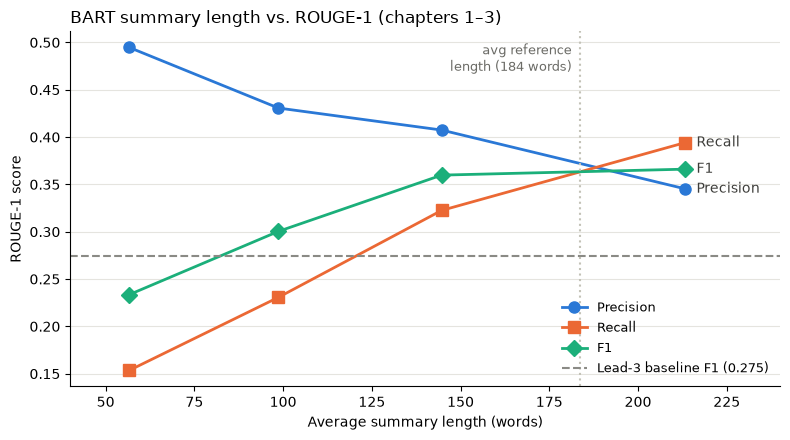

In [15]:
# Plot the trade-off.
import matplotlib.pyplot as plt

# Only the BART setups form the length sweep. Sort by length so lines read left to right.
bart_sweep_df = summarization_tuning_df.drop(index="Lead-3 baseline").sort_values("avg_words")
lead3_row = summarization_tuning_df.loc["Lead-3 baseline"]
average_reference_words = np.mean([len(reference_summaries[n].split()) for n in TUNING_CHAPTERS])

# (column, label, color, marker)
# They're distinct marker shapes so lines are tellable apart
# without color (colorblind readers, black-and-white printouts).
metric_styles = [
    ("rouge1_precision", "Precision", "#2a78d6", "o"),
    ("rouge1_recall",    "Recall",    "#eb6834", "s"),
    ("rouge1_f1",        "F1",        "#1baf7a", "D"),
]

fig, ax = plt.subplots(figsize=(8, 4.5))

for column, label, color, marker in metric_styles:
    ax.plot(bart_sweep_df["avg_words"], bart_sweep_df[column],
            color=color, marker=marker, markersize=8, linewidth=2, label=label)
    
    # Direct label at each line's right end so readers don't bounce to the legend.
    ax.annotate(label, xy=(bart_sweep_df["avg_words"].iloc[-1], bart_sweep_df[column].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=10, color="#3d3d3a")

# Baseline reference line: anything above it means "BART beats the dumb baseline".
ax.axhline(lead3_row["rouge1_f1"], color="#8a8a85", linestyle="--", linewidth=1.5,
           label=f"Lead-3 baseline F1 ({lead3_row['rouge1_f1']:.3f})")

# Where the summaries "should" land.
ax.axvline(average_reference_words, color="#c3c2b7", linestyle=":", linewidth=1.5)
ax.annotate(f"avg reference\nlength ({average_reference_words:.0f} words)",
            xy=(average_reference_words, 0.47), xytext=(-6, 0), textcoords="offset points",
            ha="right", fontsize=9, color="#6b6b66")

ax.set_title("BART summary length vs. ROUGE-1 (chapters 1–3)", loc="left", fontsize=12)
ax.set_xlabel("Average summary length (words)")
ax.set_ylabel("ROUGE-1 score")
ax.set_xlim(40, 240)
ax.grid(axis="y", color="#e5e4df", linewidth=0.8) # faint grid: helps read values without competing.
ax.spines[["top", "right"]].set_visible(False) # less chart-junk.
ax.legend(frameon=False, loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig("summarization_length_tradeoff.png", dpi=200) # Here's the high-res copy for the report.
plt.show()

# Save the tuning table too so the report numbers are reproducible without re-running anything.
summarization_tuning_df.round(3).to_csv("summarization_tuning_results.csv")

In [18]:
# Translation English to French using MarianMT.
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

EN_TO_FR_MODEL_NAME = "Helsinki-NLP/opus-mt-en-fr"

en_to_fr_tokenizer = AutoTokenizer.from_pretrained(EN_TO_FR_MODEL_NAME)
en_to_fr_model = AutoModelForSeq2SeqLM.from_pretrained(EN_TO_FR_MODEL_NAME).to(device)
en_to_fr_model.eval() # inference mode: no dropout.
en_to_fr_model.generation_config.max_length = None # Clear saved length defaults.
en_to_fr_model.generation_config.min_length = None # So only our max_new_tokens rule applies.

def split_into_sentences(text):
    """Simple regex sentence splitter: break after . ! or ? followed by whitespace.
    Imperfect on dialogue ('...?' said Alice)."""
    flattened_text = text.replace("\n\n", " ")
    
    return [sentence for sentence in re.split(r"(?<=[.!?])\s+", flattened_text) if sentence.strip()]

def translate_sentences(sentences, model, tokenizer, num_beams=4, batch_size=16, max_new_tokens=256):
    """tokenize -> generate -> decode in batches. Works for any Marian direction (EN->FR or FR->EN)."""
    translations = []
    
    for batch_start in range(0, len(sentences), batch_size):
        batch_sentences = sentences[batch_start:batch_start + batch_size]
        
        model_inputs = tokenizer(
            batch_sentences, max_length=512, truncation=True, padding=True, return_tensors="pt"
        ).to(device)
        
        with torch.no_grad():                            # no training -> skip gradient bookkeeping
            output_token_ids = model.generate(
                **model_inputs, num_beams=num_beams, max_new_tokens=max_new_tokens
            )
        
        translations.extend(
            tokenizer.decode(token_ids, skip_special_tokens=True) for token_ids in output_token_ids
        )
    
    return translations

# Test first 5 sentences of chapter 1 (skip the 'CHAPTER I. ...' heading paragraph).
chapter1_body = chapters[0].split("\n\n", 1)[-1]
sample_english_sentences = split_into_sentences(chapter1_body)[:5]

sample_start_time = time.time()
sample_french_translations = translate_sentences(sample_english_sentences, en_to_fr_model, en_to_fr_tokenizer)

print(f"Translated {len(sample_english_sentences)} sentences in {time.time() - sample_start_time:.1f}s\n")

for english_sentence, french_sentence in zip(sample_english_sentences, sample_french_translations):
    print("EN:", english_sentence)
    print("FR:", french_sentence, "\n")

Loading weights: 100%|██████████| 258/258 [00:00<00:00, 9700.42it/s]


Translated 5 sentences in 10.7s

EN: Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, “and what is the use of a book,” thought Alice “without pictures or conversations?” So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a White Rabbit with pink eyes ran close by her.
FR: Alice commençait à se lasser de s'asseoir près de sa sœur sur la banque, et de n'avoir rien à faire: une ou deux fois elle avait piraté dans le livre sa sœur lisait, mais il n'y avait pas de photos ou de conversations, et à quoi sert un livre, -a pensé Alice -a-t-elle sans photos ou conversations?- Alors elle se penchait dans son propre esprit (aussi bien qu'elle 

In [19]:
def clean_for_translation(text):
    """Remove formatting artifacts the model never saw in training."""
    text = text.replace("_", "") # Gutenberg's _italics_ markers to plain words.
    
    # Curly quotes to plain quotes: simpler symbols and lets the splitter below see them.
    text = (text.replace("“", '"').replace("”", '"')
                .replace("‘", "'").replace("’", "'"))
    
    return text

# Split after . ! or ?  -- OR after . ! ? followed by a closing quote (e.g.  ?" So ...).
# (Python lookbehinds must be fixed-width so we use two: 1-char and 2-char).
SENTENCE_BOUNDARY_PATTERN = r"(?<=[.!?])\s+|(?<=[.!?][\"'])\s+"

def split_into_sentences(text):
    """Improved splitter: handles sentences ending inside quotes."""
    flattened_text = text.replace("\n\n", " ")
    
    return [sentence for sentence in re.split(SENTENCE_BOUNDARY_PATTERN, flattened_text) if sentence.strip()]

# Same passage as before but now cleaned to direct before/after comparison.
cleaned_chapter1_body = clean_for_translation(chapter1_body)
cleaned_sample_sentences = split_into_sentences(cleaned_chapter1_body)[:6] # First old sentence now splits in 2.

print(f"Old splitter, first 5 sentences: avg {np.mean([len(s.split()) for s in sample_english_sentences]):.0f} words")
print(f"New splitter, first 6 sentences: avg {np.mean([len(s.split()) for s in cleaned_sample_sentences]):.0f} words\n")

cleaned_start_time = time.time()
cleaned_french_translations = translate_sentences(cleaned_sample_sentences, en_to_fr_model, en_to_fr_tokenizer)

print(f"Translated {len(cleaned_sample_sentences)} sentences in {time.time() - cleaned_start_time:.1f}s\n")

for english_sentence, french_sentence in zip(cleaned_sample_sentences, cleaned_french_translations):
    print("EN:", english_sentence)
    print("FR:", french_sentence, "\n")

Old splitter, first 5 sentences: avg 55 words
New splitter, first 6 sentences: avg 42 words

Translated 6 sentences in 11.2s

EN: Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, "and what is the use of a book," thought Alice "without pictures or conversations?"
FR: Alice commençait à se lasser de s'asseoir près de sa sœur à la banque, et de n'avoir rien à faire: une ou deux fois elle avait piraté dans le livre sa sœur lisait, mais il n'y avait pas de photos ou de conversations, "et à quoi sert un livre," pensa Alice "sans photos ou de conversations?" 

EN: So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a White Rabbit with pink

In [ ]:
# Translation run.

def translate_sorted_by_length(sentences, model, tokenizer, num_beams=4):
    """Batch sentences of similar length together to minimize padding waste (big win on CPU)
    then put translations back in the original sentence order."""
    sorted_indices = sorted(range(len(sentences)), key=lambda i: len(sentences[i]))
    sorted_sentences = [sentences[i] for i in sorted_indices]
    sorted_translations = translate_sentences(sorted_sentences, model, tokenizer, num_beams=num_beams)

    translations_in_original_order = [None] * len(sentences)
    
    for sorted_position, original_index in enumerate(sorted_indices):
        translations_in_original_order[original_index] = sorted_translations[sorted_position]
    
    return translations_in_original_order

def translate_chapters(chapter_numbers, num_beams=4):
    """Returns {chapter_number: {'english': [...], 'french': [...]}} and aligned sentence pairs
    so the back-translation (4c) and Bué comparison (4d) can line up sentence by sentence."""
    translations_by_chapter = {}
    
    for chapter_number in chapter_numbers:
        chapter_body = chapters[chapter_number - 1].split("\n\n", 1)[-1]   # drop the heading
        english_sentences = split_into_sentences(clean_for_translation(chapter_body))

        chapter_start_time = time.time()
        french_sentences = translate_sorted_by_length(english_sentences, en_to_fr_model,
                                                      en_to_fr_tokenizer, num_beams=num_beams)
        translations_by_chapter[chapter_number] = {"english": english_sentences, "french": french_sentences}
        
        print(f"Chapter {chapter_number}: {len(english_sentences)} sentences "
              f"in {time.time() - chapter_start_time:.1f}s")
    
    return translations_by_chapter

en_fr_translations = load_or_compute(
    "marian_en-fr_beams4_ch1-3",
    lambda: translate_chapters(TUNING_CHAPTERS, num_beams=4),
)

# Check 2 pairs from chapter 2 (a chapter we haven't looked at yet).
for english_sentence, french_sentence in list(zip(en_fr_translations[2]["english"],
                                                   en_fr_translations[2]["french"]))[10:12]:
    print("\nEN:", english_sentence)
    print("FR:", french_sentence)

Chapter 1: 80 sentences in 80.2s
Chapter 2: 112 sentences in 31.8s
Chapter 3: 111 sentences in 29.7s
Computed 'marian_en-fr_beams4_ch1-3' in 141.7s and cached it

EN: And how odd the directions will look!
FR: Et à quel point les directions seront étranges!

EN: Alice's Right Foot, Esq., Hearthrug, near the Fender, (with Alice's love).
FR: Le pied droit d'Alice, Esq., Hearthrug, près de la Fender, (avec l'amour d'Alice).


In [21]:
# Back translation check, English to French to English.
import sacrebleu

FR_TO_EN_MODEL_NAME = "Helsinki-NLP/opus-mt-fr-en"

fr_to_en_tokenizer = AutoTokenizer.from_pretrained(FR_TO_EN_MODEL_NAME)
fr_to_en_model = AutoModelForSeq2SeqLM.from_pretrained(FR_TO_EN_MODEL_NAME).to(device)
fr_to_en_model.eval()
fr_to_en_model.generation_config.max_length = None
fr_to_en_model.generation_config.min_length = None

def back_translate_chapters(translations_by_chapter, num_beams=4):
    """FR to EN for every chapter, re-using the length-sorted batching from earlier."""
    back_translations_by_chapter = {}
    
    for chapter_number, sentence_pairs in translations_by_chapter.items():
        back_translations_by_chapter[chapter_number] = translate_sorted_by_length(
            sentence_pairs["french"], fr_to_en_model, fr_to_en_tokenizer, num_beams=num_beams
        )
        print(f"Chapter {chapter_number}: back-translated")
    
    return back_translations_by_chapter

back_translations = load_or_compute(
    "marian_fr-en_backtranslation_beams4_ch1-3",
    lambda: back_translate_chapters(en_fr_translations),
)

# Score per chapter + overall. 
# sacrebleu wants: hypotheses list and a LIST of reference lists.
round_trip_rows = []
all_originals, all_round_trips = [], []

for chapter_number in TUNING_CHAPTERS:
    originals = en_fr_translations[chapter_number]["english"]
    round_trips = back_translations[chapter_number]
    
    all_originals += originals
    all_round_trips += round_trips
    
    round_trip_rows.append({
        "chapter": chapter_number,
        "sentences": len(originals),
        "BLEU": sacrebleu.corpus_bleu(round_trips, [originals]).score,
        "chrF": sacrebleu.corpus_chrf(round_trips, [originals]).score,
    })

round_trip_rows.append({
    "chapter": "all",
    "sentences": len(all_originals),
    "BLEU": sacrebleu.corpus_bleu(all_round_trips, [all_originals]).score,
    "chrF": sacrebleu.corpus_chrf(all_round_trips, [all_originals]).score,
})

round_trip_df = pd.DataFrame(round_trip_rows).set_index("chapter")

print(round_trip_df.round(1))

# Worst 3 round trips by sentence-level chrF to concrete failure examples for the report.
all_french = [fr for n in TUNING_CHAPTERS for fr in en_fr_translations[n]["french"]]
sentence_chrf_scores = [sacrebleu.sentence_chrf(rt, [orig]).score
                        for rt, orig in zip(all_round_trips, all_originals)]

for worst_index in np.argsort(sentence_chrf_scores)[:3]:
    print(f"\nchrF {sentence_chrf_scores[worst_index]:.1f}")
    print("  ORIGINAL:  ", all_originals[worst_index])
    print("  FRENCH:    ", all_french[worst_index])
    print("  ROUND TRIP:", all_round_trips[worst_index])

Loading weights: 100%|██████████| 256/256 [00:00<00:00, 1981.89it/s]


Chapter 1: back-translated
Chapter 2: back-translated
Chapter 3: back-translated
Computed 'marian_fr-en_backtranslation_beams4_ch1-3' in 191.4s and cached it
         sentences  BLEU  chrF
chapter                       
1               80  49.0  69.1
2              112  53.2  68.4
3              111  56.5  70.9
all            303  53.0  69.4

chrF 7.6
  ORIGINAL:   thump!
  FRENCH:     C'est pas vrai !
  ROUND TRIP: Oh, my God!

chrF 10.0
  ORIGINAL:   "Hold your tongue, Ma!"
  FRENCH:     "Tais-toi, maman !"
  ROUND TRIP: "Shut up, Mom!"

chrF 12.3
  ORIGINAL:   she thought.
  FRENCH:     Elle a réfléchi.
  ROUND TRIP: She's been thinking.


In [ ]:
# Score MarianMT's French against Henri Bué's 1869 human translation.
FRENCH_BOOK_URL = "https://www.gutenberg.org/cache/epub/55456/pg55456.txt" # Bué, 1869.

def clean_french_book(raw_text):
    """Same cleaning as the English book plus removing [Illustration] markers."""
    text = strip_gutenberg_boilerplate(raw_text)
    text = re.sub(r"\[Illustration[^\]]*\]", "", text)
    
    return normalize_whitespace(text)

def split_into_chapters(clean_text, heading_pattern=r"CHAPTER [IVXLC]+\.", min_chapter_chars=1000):
    """Keep pieces that START with a heading (drops front matter like Bué's preface/poem)
    and are long enough (drops table-of-contents lines). Same 12 chapters for the English book."""
    pieces = re.split(f"(?={heading_pattern})", clean_text)
    
    return [piece.strip() for piece in pieces
            if re.match(heading_pattern, piece.strip()) and len(piece.strip()) >= min_chapter_chars]

def body_paragraphs(chapter_text):
    """Cleaned paragraphs without the heading lines (English: 'CHAPTER I. Title';
    French: 'CHAPITRE PREMIER.' + 'AU FOND DU TERRIER.' as separate short paragraphs)."""
    paragraphs = clean_for_translation(chapter_text).split("\n\n")
    
    while paragraphs and len(paragraphs[0]) < 80 and (
            paragraphs[0].startswith(("CHAPTER", "CHAPITRE")) or paragraphs[0].isupper()):
        paragraphs.pop(0)
    
    return paragraphs

french_book_text = clean_french_book(download_book(FRENCH_BOOK_URL))
french_chapters = split_into_chapters(french_book_text, heading_pattern=r"CHAPITRE (?:PREMIER|[IVXLC]+)\.")

assert len(french_chapters) == 12, f"Expected 12 French chapters, got {len(french_chapters)}"

# Translate only sentences not seen before.
sentence_translation_lookup = {
    english: french
    for n in TUNING_CHAPTERS
    for english, french in zip(en_fr_translations[n]["english"], en_fr_translations[n]["french"])
}

def model_translate_paragraph(english_paragraph):
    sentences = split_into_sentences(english_paragraph)
    missing_sentences = [s for s in sentences if s not in sentence_translation_lookup]
    
    if missing_sentences:
        for sentence, french in zip(missing_sentences,
                                    translate_sentences(missing_sentences, en_to_fr_model, en_to_fr_tokenizer)):
            sentence_translation_lookup[sentence] = french
    
    return " ".join(sentence_translation_lookup[s] for s in sentences)

def align_to_bue(model_french_paragraphs, bue_paragraphs, search_window=3, min_match_chrf=25):
    """Bué sometimes merges, drops or rewrites paragraphs (e.g. replaces Carroll's poems with
    French ones) so a fixed 1:1 pairing drifts. For each model paragraph, pick the most similar
    Bué paragraph near the expected position. If two model paragraphs match the same Bué paragraph
    (Bué merged them), join them. Paragraphs with no good match (poems, wordplay) are dropped."""
    aligned_pairs = [] # List of [model_french_text, bue_index].
    expected_bue_index = 0
    
    for model_paragraph in model_french_paragraphs:
        candidate_indices = range(max(0, expected_bue_index - search_window),
                                  min(len(bue_paragraphs), expected_bue_index + search_window + 1))
        if not candidate_indices:
            break
        
        best_index = max(candidate_indices,
                         key=lambda j: sacrebleu.sentence_chrf(model_paragraph, [bue_paragraphs[j]]).score)
        best_score = sacrebleu.sentence_chrf(model_paragraph, [bue_paragraphs[best_index]]).score

        if best_score < min_match_chrf:
            expected_bue_index += 1                       # no counterpart: skip, keep moving forward
            continue
        
        if aligned_pairs and aligned_pairs[-1][1] == best_index:
            aligned_pairs[-1][0] += " " + model_paragraph  # Bué merged two paragraphs into one
        else:
            aligned_pairs.append([model_paragraph, best_index])
        
        expected_bue_index = best_index + 1
    
    return [(model_text, bue_paragraphs[bue_index]) for model_text, bue_index in aligned_pairs]

bue_rows, all_model_french, all_bue_french = [], [], []

for chapter_number in TUNING_CHAPTERS:
    english_paragraphs = body_paragraphs(chapters[chapter_number - 1])
    bue_paragraphs = body_paragraphs(french_chapters[chapter_number - 1])
    model_french_paragraphs = [model_translate_paragraph(p) for p in english_paragraphs]

    aligned_pairs = align_to_bue(model_french_paragraphs, bue_paragraphs)
    model_texts = [model_text for model_text, _ in aligned_pairs]
    bue_texts = [bue_text for _, bue_text in aligned_pairs]
    all_model_french += model_texts
    all_bue_french += bue_texts

    bue_rows.append({
        "chapter": chapter_number,
        "english_paragraphs": len(english_paragraphs),
        "aligned_pairs": len(aligned_pairs),
        "BLEU": sacrebleu.corpus_bleu(model_texts, [bue_texts]).score,
        "chrF": sacrebleu.corpus_chrf(model_texts, [bue_texts]).score,
    })

bue_rows.append({
    "chapter": "all",
    "english_paragraphs": sum(row["english_paragraphs"] for row in bue_rows),
    "aligned_pairs": len(all_model_french),
    "BLEU": sacrebleu.corpus_bleu(all_model_french, [all_bue_french]).score,
    "chrF": sacrebleu.corpus_chrf(all_model_french, [all_bue_french]).score,
})

bue_scores_df = pd.DataFrame(bue_rows).set_index("chapter")
bue_scores_df.round(1).to_csv("translation_vs_bue_scores.csv")

print(bue_scores_df.round(1))

# One aligned pair for the report.
print("\nMODEL:", all_model_french[0][:300])
print("BUÉ:  ", all_bue_french[0][:300])

         english_paragraphs  aligned_pairs  BLEU  chrF
chapter                                               
1                        30             22  16.5  47.6
2                        26             23  17.9  49.3
3                        48             43  14.4  44.4
all                     104             88  16.4  47.3

MODEL: Alice commençait à se lasser de s'asseoir près de sa sœur à la banque, et de n'avoir rien à faire: une ou deux fois elle avait piraté dans le livre sa sœur lisait, mais il n'y avait pas de photos ou de conversations, "et à quoi sert un livre," pensa Alice "sans photos ou de conversations?"
BUÉ:   ALICE, assise auprès de sa sœur sur le gazon, commençait à s'ennuyer de rester là à ne rien faire; une ou deux fois elle avait jeté les yeux sur le livre que lisait sa sœur; mais quoi! pas d'images, pas de dialogues! "La belle avance," pensait Alice, "qu'un livre sans images, sans causeries!".


In [25]:
# Tuning: beam width (num_beams=1 greedy vs num_beams=4 beam search)

# Greedy translations of ch1-3 (beams=4 version is already cached from earlier).
en_fr_translations_greedy = load_or_compute(
    "marian_en-fr_beams1_ch1-3",
    lambda: translate_chapters(TUNING_CHAPTERS, num_beams=1),
)

def score_config_against_bue(translations_by_chapter, num_beams):
    """BLEU/chrF vs Bué for one decoding config using the same paragraph alignment as earlier."""
    lookup = {english: french
              for n in TUNING_CHAPTERS
              for english, french in zip(translations_by_chapter[n]["english"],
                                         translations_by_chapter[n]["french"])}

    def translate_paragraph(english_paragraph):
        sentences = split_into_sentences(english_paragraph)
        missing = [s for s in sentences if s not in lookup]
        
        if missing: # Sentences split differently at paragraph level to translate with SAME beams.
            for s, fr in zip(missing, translate_sentences(missing, en_to_fr_model, en_to_fr_tokenizer,
                                                          num_beams=num_beams)):
                lookup[s] = fr
        
        return " ".join(lookup[s] for s in sentences)

    model_texts, bue_texts = [], []
    
    for n in TUNING_CHAPTERS:
        model_paragraphs = [translate_paragraph(p) for p in body_paragraphs(chapters[n - 1])]
        
        for model_text, bue_text in align_to_bue(model_paragraphs, body_paragraphs(french_chapters[n - 1])):
            model_texts.append(model_text)
            bue_texts.append(bue_text)
    
    return {
        "aligned_pairs": len(model_texts),
        "BLEU_vs_bue": sacrebleu.corpus_bleu(model_texts, [bue_texts]).score,
        "chrF_vs_bue": sacrebleu.corpus_chrf(model_texts, [bue_texts]).score,
    }

# Test same 60-sentence sample for both configs (cache-free timing).
speed_sample_sentences = en_fr_translations[1]["english"][:60]

def seconds_to_translate(num_beams):
    start_time = time.time()
    translate_sorted_by_length(speed_sample_sentences, en_to_fr_model, en_to_fr_tokenizer, num_beams=num_beams)
    
    return time.time() - start_time

beam_tuning_rows = []

for num_beams, translations in [(1, en_fr_translations_greedy), (4, en_fr_translations)]:
    row = {"num_beams": num_beams}
    row.update(score_config_against_bue(translations, num_beams))
    row["sec_per_60_sentences"] = seconds_to_translate(num_beams)
    beam_tuning_rows.append(row)

beam_tuning_df = pd.DataFrame(beam_tuning_rows).set_index("num_beams")
beam_tuning_df.round(2).to_csv("translation_beam_tuning.csv")

print(beam_tuning_df.round(2))

# How often does beam search actually change the output?
changed_sentences = sum(
    greedy_fr != beam_fr
    for n in TUNING_CHAPTERS
    for greedy_fr, beam_fr in zip(en_fr_translations_greedy[n]["french"], en_fr_translations[n]["french"])
)

total_sentences = sum(len(en_fr_translations[n]["french"]) for n in TUNING_CHAPTERS)

print(f"\nBeam search changed {changed_sentences}/{total_sentences} sentences "
      f"({100 * changed_sentences / total_sentences:.0f}%)")

Chapter 1: 80 sentences in 26.7s
Chapter 2: 112 sentences in 13.2s
Chapter 3: 111 sentences in 11.8s
Computed 'marian_en-fr_beams1_ch1-3' in 51.7s and cached it
           aligned_pairs  BLEU_vs_bue  chrF_vs_bue  sec_per_60_sentences
num_beams                                                               
1                     88        16.38        46.72                 12.97
4                     88        16.40        47.28                 41.64

Beam search changed 209/303 sentences (69%)


In [28]:
# Q&A system with TF-IDF retriever + DistilBERT extractive reader.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoModelForQuestionAnswering

QA_MODEL_NAME = "distilbert-base-cased-distilled-squad" # Encoder-only, fine-tuned on SQuAD.

qa_tokenizer = AutoTokenizer.from_pretrained(QA_MODEL_NAME)
qa_model = AutoModelForQuestionAnswering.from_pretrained(QA_MODEL_NAME).to(device)
qa_model.eval()

# Passages: whole book, ~300-token chunks.
QA_PASSAGE_MAX_TOKENS = 300
qa_passages = [] # List of (chapter_number, passage_text).

for chapter_number, chapter_text in enumerate(chapters, start=1):
    for passage in chunk_text_by_tokens(clean_for_translation(chapter_text), qa_tokenizer,
                                        max_tokens=QA_PASSAGE_MAX_TOKENS):
        qa_passages.append((chapter_number, passage))

print(f"{len(qa_passages)} passages indexed")

# Retriever: TF-IDF vectors with word pairs (bigrams) help match phrases like "White Rabbit".
tfidf_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
passage_tfidf_matrix = tfidf_vectorizer.fit_transform([text for _, text in qa_passages])

def retrieve_passages(question, top_k=3):
    """Indices of the top_k passages most similar to the question (cosine similarity)."""
    similarities = cosine_similarity(tfidf_vectorizer.transform([question]), passage_tfidf_matrix)[0]
    
    return list(np.argsort(similarities)[::-1][:top_k])

# Reader: the model scores every token as a possible answer START and END.
def read_answer(question, passage, max_answer_tokens=30):
    """Best (score, answer_text) span in the passage. Done by hand since v5 removed the QA pipeline."""
    encoding = qa_tokenizer(question, passage, truncation="only_second", max_length=384, stride=64,
                            return_overflowing_tokens=True, return_offsets_mapping=True,
                            padding=True, return_tensors="pt")
    offset_mapping = encoding.pop("offset_mapping") # token to character positions in passage.
    encoding.pop("overflow_to_sample_mapping", None) # not a model input.
    
    with torch.no_grad():
        model_outputs = qa_model(**{key: value.to(device) for key, value in encoding.items()})

    best_score, best_answer = -float("inf"), ""
    
    for window_index in range(len(encoding["input_ids"])): # >1 window only if passage overflows.
        start_logits = model_outputs.start_logits[window_index].cpu().numpy()
        end_logits = model_outputs.end_logits[window_index].cpu().numpy()
        sequence_ids = encoding.sequence_ids(window_index) # 0 = question token, 1 = passage token.
        offsets = offset_mapping[window_index].tolist()

        # Only check the 20 most likely starts/ends (instead of every pair) to fast.
        for start in np.argsort(start_logits)[-20:]:
            for end in np.argsort(end_logits)[-20:]:
                if sequence_ids[start] != 1 or sequence_ids[end] != 1: # answer must be in passage.
                    continue
                
                if end < start or end - start + 1 > max_answer_tokens: # valid, short span.
                    continue
                
                span_score = start_logits[start] + end_logits[end]
                
                if span_score > best_score:
                    best_score = span_score
                    best_answer = passage[offsets[start][0]:offsets[end][1]]
    
    return best_score, best_answer

def ask(question, top_k=3):
    """Chatbot: retrieve top_k passages, read each return the highest-scoring answer."""
    candidates = []
    
    for passage_index in retrieve_passages(question, top_k):
        chapter_number, passage_text = qa_passages[passage_index]
        score, answer = read_answer(question, passage_text)
        candidates.append({"answer": answer, "score": float(score), "chapter": chapter_number})
    
    return max(candidates, key=lambda candidate: candidate["score"])

# Demo.
for demo_question in ["What was written on the jar Alice took from the shelf?",
                      "What color were the White Rabbit's eyes?",
                      "What did the label on the little bottle say?"]:
    start_time = time.time()
    result = ask(demo_question)
    
    print(f"Q: {demo_question}\nA: {result['answer']}  (chapter {result['chapter']}, "
          f"score {result['score']:.1f}, {time.time() - start_time:.1f}s)\n")

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 2109.99it/s]


147 passages indexed
Q: What was written on the jar Alice took from the shelf?
A: fan and gloves  (chapter 2, score 18.2, 0.2s)

Q: What color were the White Rabbit's eyes?
A: white  (chapter 2, score 11.3, 0.2s)

Q: What did the label on the little bottle say?
A: DRINK ME  (chapter 4, score 17.7, 0.3s)



In [29]:
# Q&A evaluation with TF-IDF vs dense retriever, top_k sweep, EM/F1.
import string
from collections import Counter
from transformers import AutoModel

# Gold Q&A pairs from ch1-3 (answers must appear verbatim in the book). Last 3 = harder "why/how" questions.
qa_eval_pairs = [
    ("What was the jar labelled?", "ORANGE MARMALADE"),
    ("What colour were the White Rabbit's eyes?", "pink"),
    ("What did the Rabbit take out of its waistcoat-pocket?", "a watch"),
    ("What was the name of Alice's cat?", "Dinah"),
    ("What kind of key did Alice find on the glass table?", "a tiny golden key"),
    ("How high was the little door?", "about fifteen inches high"),
    ("What did the label on the little bottle say?", "DRINK ME"),
    ("What words were marked on the cake in currants?", "EAT ME"),
    ("What did the White Rabbit drop when Alice spoke to him?", "white kid gloves"),
    ("What did Alice's tears form around her?", "a large pool"),
    ("What nationality did Alice guess the Mouse was?", "French"),
    ("What did Alice hand round as prizes?", "comfits"),
    ("What prize did the Dodo give Alice?", "thimble"),
    ("Why didn't Alice drop the empty jar?", "for fear of killing somebody underneath"),
    ("Who suggested a Caucus-race to get everyone dry?", "Dodo"),
]

# Check every gold answer must exist in the (cleaned) book text or EM can never be 1.
cleaned_book_text_lower = clean_for_translation(book_text).lower()
missing_answers = [answer for _, answer in qa_eval_pairs if answer.lower() not in cleaned_book_text_lower]

print("Answers not found verbatim (fix these):", missing_answers or "none")

# SQuAD-style metrics.
def normalize_answer(text):
    """Lowercase, drop punctuation and articles, collapse spaces to fair string comparison."""
    text = "".join(ch for ch in text.lower() if ch not in string.punctuation)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    
    return " ".join(text.split())

def exact_match(prediction, gold):
    return float(normalize_answer(prediction) == normalize_answer(gold))

def token_f1(prediction, gold):
    """Partial credit: word overlap between prediction and gold."""
    prediction_tokens, gold_tokens = normalize_answer(prediction).split(), normalize_answer(gold).split()
    overlap = sum((Counter(prediction_tokens) & Counter(gold_tokens)).values())
    
    if overlap == 0:
        return 0.0
    
    precision, recall = overlap / len(prediction_tokens), overlap / len(gold_tokens)
    
    return 2 * precision * recall / (precision + recall)

# Dense retriever: MiniLM sentence embeddings (meaning vectors), mean-pooled, unit length.
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_tokenizer = AutoTokenizer.from_pretrained(EMBEDDING_MODEL_NAME)
embedding_model = AutoModel.from_pretrained(EMBEDDING_MODEL_NAME).to(device).eval()

def embed_texts(texts, batch_size=32):
    all_embeddings = []
    
    for batch_start in range(0, len(texts), batch_size):
        batch = embedding_tokenizer(texts[batch_start:batch_start + batch_size], padding=True,
                                    truncation=True, max_length=512, return_tensors="pt").to(device)
        with torch.no_grad():
            token_vectors = embedding_model(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float() # Ignore padding tokens.
        mean_vectors = (token_vectors * mask).sum(1) / mask.sum(1) # Average token vectors.
        all_embeddings.append(torch.nn.functional.normalize(mean_vectors, dim=1).cpu())
    
    return torch.cat(all_embeddings).numpy()

passage_embeddings = load_or_compute("minilm_passage_embeddings_300tok",
                                     lambda: embed_texts([text for _, text in qa_passages]))

def retrieve_dense(question, top_k=3):
    similarities = passage_embeddings @ embed_texts([question])[0] # cosine (vectors are unit length).
    
    return list(np.argsort(similarities)[::-1][:top_k])

RETRIEVERS = {"tfidf": retrieve_passages, "dense": retrieve_dense}

def ask_with(question, retriever_name, top_k):
    """Same chatbot as earlier but with a pluggable retriever. Also returns retrieved indices for diagnostics."""
    retrieved_indices = RETRIEVERS[retriever_name](question, top_k)
    candidates = []
    
    for passage_index in retrieved_indices:
        score, answer = read_answer(question, qa_passages[passage_index][1])
        candidates.append({"answer": answer, "score": float(score),
                           "chapter": qa_passages[passage_index][0]})
    
    return max(candidates, key=lambda c: c["score"]), retrieved_indices

# Sweep: retriever x top_k.
qa_tuning_rows, qa_prediction_rows = [], []

for retriever_name in RETRIEVERS:
    for top_k in [1, 3, 5, 10]:
        exact_matches, f1_scores, retrieval_hits = [], [], []
        
        for question, gold_answer in qa_eval_pairs:
            best, retrieved_indices = ask_with(question, retriever_name, top_k)
            exact_matches.append(exact_match(best["answer"], gold_answer))
            
            f1_scores.append(token_f1(best["answer"], gold_answer))
            
            # Retrieval hit = gold answer text appears in ANY retrieved passage (separates retriever vs reader errors).
            retrieval_hits.append(float(any(gold_answer.lower() in qa_passages[i][1].lower()
                                            for i in retrieved_indices)))
            
            qa_prediction_rows.append({"retriever": retriever_name, "top_k": top_k, "question": question,
                                       "gold": gold_answer, "predicted": best["answer"]})
        
        qa_tuning_rows.append({"retriever": retriever_name, "top_k": top_k,
                               "retrieval_hit_rate": np.mean(retrieval_hits),
                               "EM": np.mean(exact_matches), "F1": np.mean(f1_scores)})

qa_tuning_df = pd.DataFrame(qa_tuning_rows).set_index(["retriever", "top_k"])
qa_predictions_df = pd.DataFrame(qa_prediction_rows)
qa_tuning_df.round(3).to_csv("qa_tuning_results.csv")
qa_predictions_df.to_csv("qa_predictions.csv", index=False)

print(qa_tuning_df.round(3))

# Best config's per-question answers for the report's error analysis section.
best_retriever, best_top_k = qa_tuning_df["F1"].idxmax()

print(f"\nBest config: {best_retriever}, top_k={best_top_k}")
print(qa_predictions_df.query("retriever == @best_retriever and top_k == @best_top_k")
      [["question", "gold", "predicted"]].to_string(index=False))

Answers not found verbatim (fix these): none


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1983.30it/s]


Computed 'minilm_passage_embeddings_300tok' in 4.1s and cached it
                 retrieval_hit_rate     EM     F1
retriever top_k                                  
tfidf     1                   0.533  0.333  0.481
          3                   0.733  0.333  0.542
          5                   0.800  0.400  0.608
          10                  1.000  0.533  0.697
dense     1                   0.667  0.267  0.488
          3                   0.867  0.467  0.708
          5                   1.000  0.533  0.731
          10                  1.000  0.533  0.731

Best config: dense, top_k=5
                                               question                                    gold                           predicted
                             What was the jar labelled?                        ORANGE MARMALADE                    ORANGE MARMALADE
              What colour were the White Rabbit's eyes?                                    pink                                pink
  What di

In [30]:
# Text generation with GPT-2 decoding sweep + perplexity.
from transformers import AutoModelForCausalLM

def load_causal_lm(model_name):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name).to(device).eval()
    model.generation_config.max_length = None              
    model.generation_config.pad_token_id = tokenizer.eos_token_id # GPT-2 has no pad token.
    
    return tokenizer, model

gpt2_tokenizer, gpt2_model = load_causal_lm("gpt2") # decoder-only, 124M params.

# Perplexity: how "surprised" a model is by real text. exp(average loss per token). Lower = better.
def perplexity(text, model, tokenizer, window_tokens=512, stride_tokens=256):
    """Sliding window so long text fits GPT-2's 1024-token limit. Overlap gives each window context."""
    input_ids = tokenizer(text, return_tensors="pt").input_ids
    total_negative_log_likelihood, total_scored_tokens, previous_end = 0.0, 0, 0
    
    for window_start in range(0, input_ids.size(1), stride_tokens):
        window_end = min(window_start + window_tokens, input_ids.size(1))
        new_token_count = window_end - previous_end # Only score tokens not scored before.
        window_ids = input_ids[:, window_start:window_end].to(device)
        
        labels = window_ids.clone()
        labels[:, :-new_token_count] = -100 # -100 = ignore (context-only tokens).
        
        with torch.no_grad():
            loss = model(window_ids, labels=labels).loss
        
        total_negative_log_likelihood += loss.item() * new_token_count
        total_scored_tokens += new_token_count
        
        previous_end = window_end
        
        if window_end == input_ids.size(1):
            break
    
    return float(np.exp(total_negative_log_likelihood / total_scored_tokens))

# Perplexity on the book itself: GPT-2 vs smaller DistilGPT-2. Use as model comparison for the report.
ch1_to_3_text = " ".join(body for n in TUNING_CHAPTERS
                         for body in ["\n\n".join(body_paragraphs(chapters[n - 1]))])

def book_perplexity_by_model():
    results = {"gpt2": perplexity(ch1_to_3_text, gpt2_model, gpt2_tokenizer)}
    distil_tokenizer, distil_model = load_causal_lm("distilgpt2")    # 82M params, faster
    results["distilgpt2"] = perplexity(ch1_to_3_text, distil_model, distil_tokenizer)
    
    return results

book_perplexities = load_or_compute("book_perplexity_ch1-3_gpt2_vs_distilgpt2", book_perplexity_by_model)

print("Perplexity on chapters 1-3:", {k: round(v, 1) for k, v in book_perplexities.items()})

# Decoding sweep from a seed sentence from the book.
SEED_TEXT = "Alice was beginning to get very tired of sitting by her sister on the bank,"
NEW_TOKENS = 80
SAMPLES_PER_CONFIG = 3 # Sampling is random to several samples. Deterministic configs give 1.

decoding_configs = {
    "greedy":             dict(do_sample=False),
    "beam_4":             dict(do_sample=False, num_beams=4, no_repeat_ngram_size=3),
    "top_k_50":           dict(do_sample=True, top_k=50),
    "top_p_0.9_temp_0.8": dict(do_sample=True, top_p=0.9, temperature=0.8),
    "top_p_0.9_temp_1.2": dict(do_sample=True, top_p=0.9, temperature=1.2),
}

def generate_continuations(config):
    set_seed(RANDOM_SEED) # Reproducible samples.
    seed_inputs = gpt2_tokenizer(SEED_TEXT, return_tensors="pt").to(device)
    sample_count = SAMPLES_PER_CONFIG if config.get("do_sample") else 1
    
    with torch.no_grad():
        output_ids = gpt2_model.generate(**seed_inputs, max_new_tokens=NEW_TOKENS,
                                         num_return_sequences=sample_count, **config)
    
    seed_length = seed_inputs["input_ids"].shape[1]
    
    return [gpt2_tokenizer.decode(ids[seed_length:], skip_special_tokens=True) for ids in output_ids]

def distinct_2(texts):
    """Diversity: share of unique word pairs. Low = repetitive ('the the the...')."""
    bigrams = [tuple(words[i:i + 2]) for t in texts for words in [t.split()] for i in range(len(words) - 1)]
    
    return len(set(bigrams)) / max(len(bigrams), 1)

generation_rows, generated_samples = [], {}

for config_name, config in decoding_configs.items():
    continuations = load_or_compute(f"gpt2_gen_{config_name}_{NEW_TOKENS}tok",
                                    lambda: generate_continuations(config))
    
    generated_samples[config_name] = continuations
    generation_rows.append({
        "config": config_name,
        # perplexity of (seed + continuation) under GPT-2: very low often = bland/repetitive.
        "gen_perplexity": np.mean([perplexity(SEED_TEXT + c, gpt2_model, gpt2_tokenizer) for c in continuations]),
        "distinct_2": distinct_2(continuations),
        "avg_words": np.mean([len(c.split()) for c in continuations]),
    })

generation_df = pd.DataFrame(generation_rows).set_index("config")
generation_df.round(3).to_csv("generation_decoding_sweep.csv")

print(generation_df.round(2))

for config_name, continuations in generated_samples.items():
    print(f"\n--- {config_name} ---\n{SEED_TEXT}{continuations[0]}")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1577.03it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (7790 > 1024). Running this sequence through the model will result in indexing errors
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
Loading weights: 100%|██████████| 76/76 [00:00<00:00, 2100.37it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (7790 > 1024). Running this sequence through the model will result in indexing errors


Computed 'book_perplexity_ch1-3_gpt2_vs_distilgpt2' in 38.4s and cached it
Perplexity on chapters 1-3: {'gpt2': 20.6, 'distilgpt2': 35.7}
Computed 'gpt2_gen_greedy_80tok' in 2.9s and cached it
Computed 'gpt2_gen_beam_4_80tok' in 4.7s and cached it
Computed 'gpt2_gen_top_k_50_80tok' in 4.7s and cached it
Computed 'gpt2_gen_top_p_0.9_temp_0.8_80tok' in 4.7s and cached it
Computed 'gpt2_gen_top_p_0.9_temp_1.2_80tok' in 4.8s and cached it
                    gen_perplexity  distinct_2  avg_words
config                                                   
greedy                        2.65        0.15      69.00
beam_4                        5.04        0.98      57.00
top_k_50                     19.72        0.97      67.33
top_p_0.9_temp_0.8            9.64        0.94      67.67
top_p_0.9_temp_1.2           18.11        0.96      68.00

--- greedy ---
Alice was beginning to get very tired of sitting by her sister on the bank, and she was getting tired of being alone. She was tired of bein

In [32]:
# Final results table + requirements.txt + README.
from importlib.metadata import version, PackageNotFoundError

# Final results: one row per task (best/chosen config), pulled from earlier result tables.
best_summary = summarization_tuning_df.loc["BART reduce min180"]
lead3_summary = summarization_tuning_df.loc["Lead-3 baseline"]
best_qa = qa_tuning_df.loc[("dense", 5)]
best_generation = generation_df.loc["top_p_0.9_temp_0.8"]

final_results_df = pd.DataFrame([
    ["Summarization", "facebook/bart-large-cnn", "map-reduce, beams=4, final min 180 tok",
     f"ROUGE-1 F1 {best_summary['rouge1_f1']:.3f} | ROUGE-2 F1 {best_summary['rouge2_f1']:.3f} | "
     f"ROUGE-L F1 {best_summary['rougeL_f1']:.3f} (Lead-3 baseline ROUGE-1 F1 {lead3_summary['rouge1_f1']:.3f})"],
    ["Translation EN→FR", "Helsinki-NLP/opus-mt-en-fr", "sentence-level, beams=4",
     f"Round-trip BLEU {round_trip_df.loc['all', 'BLEU']:.1f} / chrF {round_trip_df.loc['all', 'chrF']:.1f} | "
     f"vs Bué 1869 BLEU {bue_scores_df.loc['all', 'BLEU']:.1f} / chrF {bue_scores_df.loc['all', 'chrF']:.1f}"],
    ["Question answering", f"{QA_MODEL_NAME} + MiniLM retriever", "dense retrieval, top_k=5",
     f"EM {best_qa['EM']:.3f} | F1 {best_qa['F1']:.3f} | retrieval hit rate {best_qa['retrieval_hit_rate']:.3f}"],
    ["Text generation", "gpt2", "top-p 0.9, temperature 0.8, 80 new tokens",
     f"Book perplexity {book_perplexities['gpt2']:.1f} (distilgpt2 {book_perplexities['distilgpt2']:.1f}) | "
     f"generated perplexity {best_generation['gen_perplexity']:.1f} | distinct-2 {best_generation['distinct_2']:.2f}"],
], columns=["task", "model", "chosen_setting", "results"])

final_results_df.to_csv("final_results.csv", index=False)
print(final_results_df.to_string(index=False))

# requirements.txt pinned to the exact versions used here.
REQUIRED_PACKAGES = ["torch", "transformers", "evaluate", "rouge_score", "sacrebleu", "sentencepiece",
                     "accelerate", "scikit-learn", "pandas", "numpy", "matplotlib", "requests"]

requirement_lines = []

for package_name in REQUIRED_PACKAGES:
    try:
        requirement_lines.append(f"{package_name}=={version(package_name)}")
    except PackageNotFoundError:
        requirement_lines.append(package_name)          # not installed here -> unpinned

with open("requirements.txt", "w") as requirements_file:
    requirements_file.write("\n".join(requirement_lines) + "\n")

print("\nrequirements.txt:\n" + "\n".join(requirement_lines))

# README.md
readme_text = f"""# NLP Using Transformers

Four transformer NLP tasks on *{BOOK_TITLE}* (Project Gutenberg #11):
text summarization, English→French translation, question answering (chatbot), and text generation.

## Data (global URLs only — nothing to download manually)
- English book: {BOOK_URL}
- French reference translation (Henri Bué, 1869, Gutenberg #55456): {FRENCH_BOOK_URL}
- All models download automatically from the Hugging Face Hub.

## How to run
1. Python 3.10+. Install dependencies:  `pip install -r requirements.txt`
2. Open the notebook in Jupyter, VS Code, or Google Colab.
3. Run all cells top to bottom (Kernel → Restart & Run All).
   - GPU is optional. On a 6-core CPU, a full run from scratch takes roughly 20–30 minutes.
   - Heavy results are cached in `cache/` as `.pkl` files; reruns load them in seconds.
     Delete `cache/` to recompute everything from scratch.

## Models
| Task | Model | Architecture |
|---|---|---|
| Summarization | facebook/bart-large-cnn | encoder-decoder |
| Translation | Helsinki-NLP/opus-mt-en-fr (+ opus-mt-fr-en for back-translation) | encoder-decoder |
| Q&A reader | {QA_MODEL_NAME} | encoder-only |
| Q&A retriever | {EMBEDDING_MODEL_NAME} (+ TF-IDF baseline) | encoder-only |
| Generation | gpt2 (+ distilgpt2 for comparison) | decoder-only |

## Outputs
`final_results.csv`, `summarization_tuning_results.csv`, `summarization_length_tradeoff.png`,
`translation_vs_bue_scores.csv`, `translation_beam_tuning.csv`, `qa_tuning_results.csv`,
`qa_predictions.csv`, `generation_decoding_sweep.csv`

## Assumptions
- Transformers v5 removed the summarization, translation, and question-answering pipelines, so
  models are called directly (`AutoModelForSeq2SeqLM`, `AutoModelForQuestionAnswering`,
  `AutoModelForCausalLM` + `generate()`). Pretrained weights are unchanged.
- Evaluation uses chapters 1–3. Reference summaries and Q&A pairs were written by the author.
- Translation is evaluated two ways: back-translation (EN→FR→EN) and against Bué's 1869 translation,
  paragraph-aligned automatically with chrF similarity; unmatched paragraphs (rewritten poems/wordplay) are excluded.
- Sentences are split with a regex, which can fragment dialogue.
- Random seed: {RANDOM_SEED}.
"""

with open("README.md", "w", encoding="utf-8") as readme_file:
    readme_file.write(readme_text)

print("\nWrote README.md, requirements.txt, final_results.csv")

              task                                                    model                            chosen_setting                                                                                   results
     Summarization                                  facebook/bart-large-cnn    map-reduce, beams=4, final min 180 tok ROUGE-1 F1 0.360 | ROUGE-2 F1 0.047 | ROUGE-L F1 0.151 (Lead-3 baseline ROUGE-1 F1 0.275)
 Translation EN→FR                               Helsinki-NLP/opus-mt-en-fr                   sentence-level, beams=4                      Round-trip BLEU 53.0 / chrF 69.4 | vs Bué 1869 BLEU 16.4 / chrF 47.3
Question answering distilbert-base-cased-distilled-squad + MiniLM retriever                  dense retrieval, top_k=5                                            EM 0.533 | F1 0.731 | retrieval hit rate 1.000
   Text generation                                                     gpt2 top-p 0.9, temperature 0.8, 80 new tokens       Book perplexity 20.6 (distilgpt2 35.7) | gen